# Analyse Exploratoire des Données (EDA) — IRM Alzheimer (OASIS-1)

Ce notebook présente une analyse exploratoire complète du jeu de données d'images IRM cérébrales issues de la cohorte **OASIS-1**, réparties en 4 classes de sévérité clinique :
- `Non Demented`
- `Very mild Dementia`
- `Mild Dementia`
- `Moderate Dementia`

### Objectifs de l'EDA
1. **Environnement matériel** : vérifier la disponibilité du GPU Intel Iris (XPU) via l'environnement Conda `tf-iris-fedora`.
2. **Inventaire & structure hiérarchique** : analyser la hiérarchie *Patient (`subject_id`) → Session (`MR`) → Volume (`mpr`) → Coupe (`slice`)* et détecter tout risque de **data leakage**.
3. **Déséquilibre des classes** : quantifier le déséquilibre au niveau des images, des volumes et des patients uniques.
4. **Qualité et propriétés des images** : dimensions, modes couleur, redondance des canaux RGB, fichiers corrompus, doublons exacts.
5. **Exploration visuelle & statistique** : grilles d'exemples, séquences de coupes, intensités des pixels, ratio de fond noir, images moyennes et écarts-types par classe.
6. **Structure latente (PCA)** : identifier ce qui domine la variance visuelle (classe clinique, position de la coupe ou identité du patient).
7. **Recommandations de modélisation** : stratégie de split, prétraitement, gestion du déséquilibre et métriques adaptées.


## 1. Configuration et Vérification de l'Environnement (GPU Intel XPU)


In [1]:
import os
import re
import hashlib
import warnings
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

warnings.filterwarnings("ignore")

# Style Matplotlib propre et lisible
plt.rcParams.update({
    "figure.figsize": (11, 5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

# Ordre clinique logique des classes (de sain à modéré)
CLASS_ORDER = [
    "Non Demented",
    "Very mild Dementia",
    "Mild Dementia",
    "Moderate Dementia",
]
CLASS_COLORS = {
    "Non Demented": "#2a9d8f",
    "Very mild Dementia": "#e9c46a",
    "Mild Dementia": "#f4a261",
    "Moderate Dementia": "#e76f51",
}

DATA_DIR = Path("/home/timba/Téléchargements/Data")
SEED = 42
rng = np.random.default_rng(SEED)

print(f"Répertoire des données : {DATA_DIR}")
print(f"Classes détectées      : {sorted([d.name for d in DATA_DIR.iterdir() if d.is_dir()])}")


Répertoire des données : /home/timba/Téléchargements/Data
Classes détectées      : ['Mild Dementia', 'Moderate Dementia', 'Non Demented', 'Very mild Dementia']


In [2]:
# Vérification TensorFlow + GPU Intel Iris (XPU via ITEX)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf

print(f"TensorFlow version : {tf.__version__}")
print("Périphériques physiques détectés :")
for dev in tf.config.list_physical_devices():
    print(f"  - {dev.device_type}: {dev.name}")

xpu_devices = tf.config.list_physical_devices("XPU") + tf.config.list_physical_devices("GPU")
if xpu_devices:
    print(f"\n✅ Accélérateur détecté : {xpu_devices[0].name}")
    # Mini test de calcul sur accélérateur
    with tf.device(xpu_devices[0].name.replace("/physical_device:", "")):
        a = tf.random.normal((512, 512))
        b = tf.matmul(a, a)
    print(f"   Test matmul (512x512) réussi — norme = {tf.linalg.norm(b).numpy():.2f}")
else:
    print("\n⚠️ Aucun GPU/XPU détecté, exécution sur CPU.")


2026-11-20 14:32:37.822394: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-20 14:32:37.822424: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-20 14:32:37.823084: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


2026-11-20 14:32:39.428368: I itex/core/wrapper/itex_gpu_wrapper.cc:38] Intel Extension for Tensorflow* GPU backend is loaded.
2026-11-20 14:32:39.469053: I itex/core/devices/gpu/itex_gpu_runtime.cc:130] Selected platform: Intel(R) oneAPI Unified Runtime over Level-Zero
2026-11-20 14:32:39.469084: I itex/core/devices/gpu/itex_gpu_runtime.cc:155] number of sub-devices is zero, expose root device.


TensorFlow version : 2.15.1
Périphériques physiques détectés :
  - CPU: /physical_device:CPU:0
  - XPU: /physical_device:XPU:0

✅ Accélérateur détecté : /physical_device:XPU:0


   Test matmul (512x512) réussi — norme = 11630.33


## 2. Inventaire et Structure Hiérarchique des Données (OASIS-1)

Les fichiers suivent la convention de nommage OASIS-1 :
`OAS1_<subject_id>_<session>_<mpr_scan>_<slice_idx>.jpg`

Parcourons l'ensemble des fichiers pour construire un `DataFrame` complet de métadonnées et vérifier :
- l'intégrité du nommage et des extensions ;
- le nombre de coupes par volume MPR ;
- l'absence de chevauchement de patients entre classes.


In [3]:
FILENAME_PATTERN = re.compile(r"^(OAS1_\d+)_(MR\d+)_(mpr-\d+)_(\d+)\.(\w+)$")

records = []
non_matching = []

for cls in CLASS_ORDER:
    cls_dir = DATA_DIR / cls
    for path in cls_dir.iterdir():
        if not path.is_file():
            continue
        m = FILENAME_PATTERN.match(path.name)
        size_bytes = path.stat().st_size
        if m:
            subj, session, mpr, slc, ext = m.groups()
            records.append({
                "filepath": str(path),
                "filename": path.name,
                "label": cls,
                "subject_id": subj,
                "session": session,
                "mpr_id": mpr,
                "volume_id": f"{subj}_{session}_{mpr}",
                "slice_idx": int(slc),
                "ext": ext.lower(),
                "file_size_kb": size_bytes / 1024.0,
            })
        else:
            non_matching.append((cls, path.name))

df = pd.DataFrame(records)
df["label"] = pd.Categorical(df["label"], categories=CLASS_ORDER, ordered=True)

print(f"Nombre total d'images indexées : {len(df):,}")
print(f"Fichiers non conformes au regex: {len(non_matching)}")
print(f"Extensions uniques             : {df['ext'].value_counts().to_dict()}")
print(f"Patients uniques (subject_id)  : {df['subject_id'].nunique()}")
print(f"Volumes uniques (MPR)          : {df['volume_id'].nunique()}")
print(f"Sessions uniques               : {df['session'].value_counts().to_dict()}")
print(f"Scans MPR uniques              : {df['mpr_id'].value_counts().sort_index().to_dict()}")
print(f"Plage d'indices de coupes      : {df['slice_idx'].min()} à {df['slice_idx'].max()} ({df['slice_idx'].nunique()} coupes distinctes)")
df.head()


Nombre total d'images indexées : 86,437
Fichiers non conformes au regex: 0
Extensions uniques             : {'jpg': 86437}
Patients uniques (subject_id)  : 347
Volumes uniques (MPR)          : 1417
Sessions uniques               : {'MR1': 81801, 'MR2': 4636}
Scans MPR uniques              : {'mpr-1': 22265, 'mpr-2': 22326, 'mpr-3': 22265, 'mpr-4': 19459, 'mpr-5': 61, 'mpr-6': 61}
Plage d'indices de coupes      : 100 à 160 (61 coupes distinctes)


,filepath,filename,label,subject_id,session,mpr_id,volume_id,slice_idx,ext,file_size_kb
0,/home/timba/Téléchargements/Data/Non Demented/...,OAS1_0001_MR1_mpr-1_100.jpg,Non Demented,OAS1_0001,MR1,mpr-1,OAS1_0001_MR1_mpr-1,100,jpg,15.237305
1,/home/timba/Téléchargements/Data/Non Demented/...,OAS1_0001_MR1_mpr-1_101.jpg,Non Demented,OAS1_0001,MR1,mpr-1,OAS1_0001_MR1_mpr-1,101,jpg,15.827148
2,/home/timba/Téléchargements/Data/Non Demented/...,OAS1_0001_MR1_mpr-1_102.jpg,Non Demented,OAS1_0001,MR1,mpr-1,OAS1_0001_MR1_mpr-1,102,jpg,15.884766
3,/home/timba/Téléchargements/Data/Non Demented/...,OAS1_0001_MR1_mpr-1_103.jpg,Non Demented,OAS1_0001,MR1,mpr-1,OAS1_0001_MR1_mpr-1,103,jpg,15.362305
4,/home/timba/Téléchargements/Data/Non Demented/...,OAS1_0001_MR1_mpr-1_104.jpg,Non Demented,OAS1_0001,MR1,mpr-1,OAS1_0001_MR1_mpr-1,104,jpg,15.337891


In [4]:
# Vérification de l'intégrité des volumes et du chevauchement de patients entre classes
slices_per_vol = df.groupby("volume_id")["slice_idx"].agg(["count", "min", "max", "nunique"])
print("Distribution du nombre de coupes par volume MPR :")
print(slices_per_vol["count"].value_counts().to_dict())
print(f"Tous les volumes ont-ils exactement les coupes 100..160 ? "
      f"{(slices_per_vol['count'].eq(61) & slices_per_vol['min'].eq(100) & slices_per_vol['max'].eq(160)).all()}")

# Chevauchement de patients entre classes
subj_classes = df.groupby("subject_id")["label"].nunique()
multi_class_subjs = subj_classes[subj_classes > 1]
print(f"\nPatients présents dans plusieurs classes : {len(multi_class_subjs)}")

# Nombre de volumes MPR par patient
vols_per_subj = df.groupby(["label", "subject_id"], observed=True)["volume_id"].nunique().reset_index(name="n_volumes")
print("\nNombre de volumes MPR par patient (statistiques par classe) :")
display(vols_per_subj.groupby("label", observed=True)["n_volumes"].describe().round(2))


Distribution du nombre de coupes par volume MPR :
{61: 1417}
Tous les volumes ont-ils exactement les coupes 100..160 ? True

Patients présents dans plusieurs classes : 0

Nombre de volumes MPR par patient (statistiques par classe) :


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Non Demented,266.0,4.14,1.14,2.0,4.0,4.0,4.0,8.0
Very mild Dementia,58.0,3.88,0.33,3.0,4.0,4.0,4.0,4.0
Mild Dementia,21.0,3.90,0.30,3.0,4.0,4.0,4.0,4.0
Moderate Dementia,2.0,4.00,0.00,4.0,4.0,4.0,4.0,4.0


## 3. Déséquilibre des Classes : Images vs Volumes vs Patients

En imagerie médicale 3D découpée en coupes 2D, analyser uniquement le nombre d'images peut être très trompeur. Il est indispensable de comparer la distribution à trois granularités : **images**, **volumes MPR** et **patients uniques**.


,label,n_images,n_volumes,n_patients,size_mb,pct_images,pct_patients,imgs_per_patient,imbalance_ratio_vs_maj
0,Non Demented,67222,1102,266,1005.81,77.77,76.66,252.71,1.00
1,Very mild Dementia,13725,225,58,204.89,15.88,16.71,236.64,4.90
2,Mild Dementia,5002,82,21,75.34,5.79,6.05,238.19,13.44
3,Moderate Dementia,488,8,2,7.48,0.56,0.58,244.00,137.75


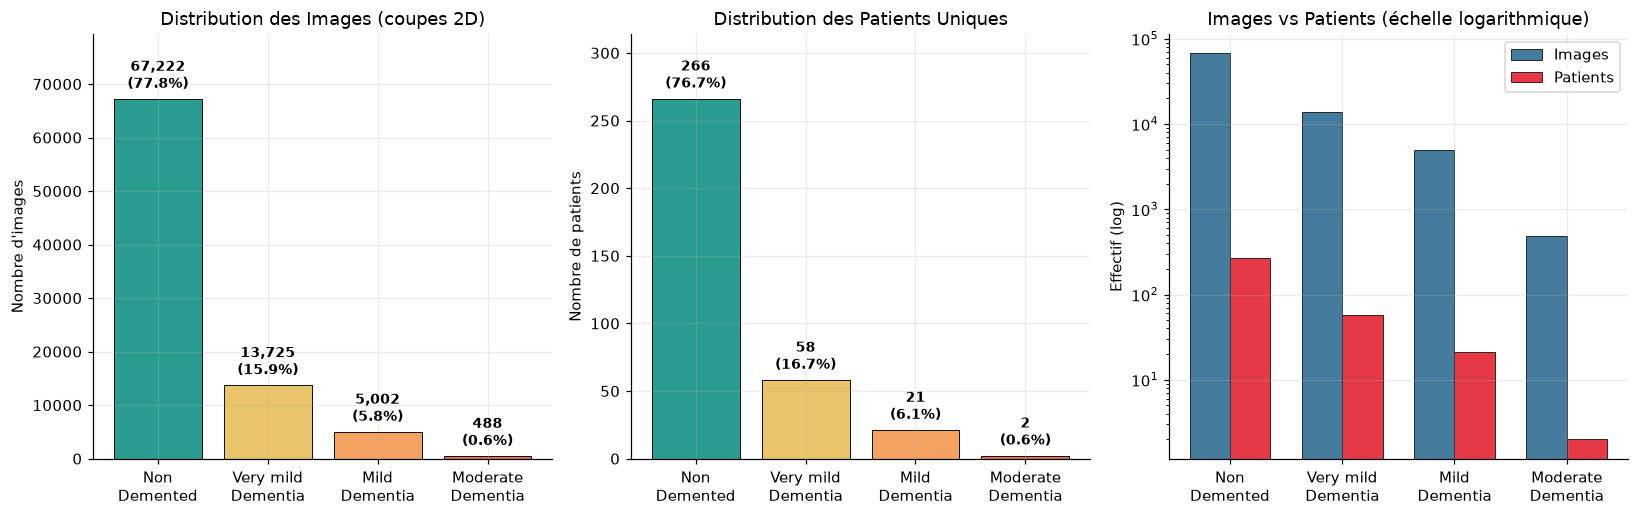

⚠️ Zoom sur la classe critique 'Moderate Dementia' :


,n_volumes,n_images,mprs
subject_id,,,
OAS1_0308,4,244,"[mpr-1, mpr-2, mpr-3, mpr-4]"
OAS1_0351,4,244,"[mpr-1, mpr-2, mpr-3, mpr-4]"


In [5]:
summary = (
    df.groupby("label", observed=True)
    .agg(
        n_images=("filename", "count"),
        n_volumes=("volume_id", "nunique"),
        n_patients=("subject_id", "nunique"),
        size_mb=("file_size_kb", lambda s: s.sum() / 1024.0),
    )
    .reset_index()
)
summary["pct_images"] = 100 * summary["n_images"] / summary["n_images"].sum()
summary["pct_patients"] = 100 * summary["n_patients"] / summary["n_patients"].sum()
summary["imgs_per_patient"] = summary["n_images"] / summary["n_patients"]
summary["imbalance_ratio_vs_maj"] = summary["n_images"].max() / summary["n_images"]

display(summary.round(2))

# Visualisation comparative
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
colors = [CLASS_COLORS[c] for c in summary["label"]]
short_labels = ["Non\nDemented", "Very mild\nDementia", "Mild\nDementia", "Moderate\nDementia"]

# 1. Nombre d'images
bars1 = axes[0].bar(short_labels, summary["n_images"], color=colors, edgecolor="black", linewidth=0.6)
axes[0].set_title("Distribution des Images (coupes 2D)")
axes[0].set_ylabel("Nombre d'images")
for bar, val, pct in zip(bars1, summary["n_images"], summary["pct_images"]):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 1200, f"{val:,}\n({pct:.1f}%)",
                 ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_ylim(0, summary["n_images"].max() * 1.18)

# 2. Nombre de patients uniques
bars2 = axes[1].bar(short_labels, summary["n_patients"], color=colors, edgecolor="black", linewidth=0.6)
axes[1].set_title("Distribution des Patients Uniques")
axes[1].set_ylabel("Nombre de patients")
for bar, val, pct in zip(bars2, summary["n_patients"], summary["pct_patients"]):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 5, f"{val}\n({pct:.1f}%)",
                 ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[1].set_ylim(0, summary["n_patients"].max() * 1.18)

# 3. Images (échelle log) vs Patients
x = np.arange(len(short_labels))
w = 0.36
axes[2].bar(x - w/2, summary["n_images"], width=w, label="Images", color="#457b9d", edgecolor="black", linewidth=0.5)
axes[2].bar(x + w/2, summary["n_patients"], width=w, label="Patients", color="#e63946", edgecolor="black", linewidth=0.5)
axes[2].set_yscale("log")
axes[2].set_xticks(x)
axes[2].set_xticklabels(short_labels)
axes[2].set_title("Images vs Patients (échelle logarithmique)")
axes[2].set_ylabel("Effectif (log)")
axes[2].legend()

plt.tight_layout()
plt.show()

# Zoom sur les patients Moderate Dementia
mod_subjs = df[df["label"] == "Moderate Dementia"].groupby("subject_id").agg(
    n_volumes=("volume_id", "nunique"),
    n_images=("filename", "count"),
    mprs=("mpr_id", lambda s: sorted(s.unique()))
)
print("⚠️ Zoom sur la classe critique 'Moderate Dementia' :")
display(mod_subjs)


> **Point critique n°1 — Risque majeur de Data Leakage :**
> Chaque patient possède en moyenne **~4 volumes MPR × 61 coupes ≈ 244 images** très fortement corrélées (coupes adjacentes espacées de 1 mm + scans répétés du même cerveau). Un `train_test_split` aléatoire au niveau des images place le même cerveau en train et en test, ce qui gonfle artificiellement l'accuracy (~99 %) sans aucune capacité de généralisation à de nouveaux patients.
>
> **Point critique n°2 — Classe `Moderate Dementia` :**
> Elle ne contient que **2 patients uniques** (`OAS1_0308` et `OAS1_0351`, 488 images au total, soit **0,56 %** du dataset). Cela représente un ratio de déséquilibre de **137,7:1** par rapport à `Non Demented` et rend une validation croisée à plus de 2 folds impossible au niveau patient sur cette classe sans regroupement ou stratégie dédiée.


## 4. Intégrité, Dimensions, Canaux Couleur et Doublons

Vérifions rapidement les métadonnées JPEG de **toutes les 86 437 images** (dimensions, mode couleur, fichiers illisibles), puis vérifions sur un échantillon stratifié si les 3 canaux RGB sont réellement distincts ou s'il s'agit d'images en niveaux de gris dupliquées sur 3 canaux, et recherchons d'éventuels doublons exacts (MD5).


In [6]:
# Lecture rapide des en-têtes PIL (sans décodage complet) sur les 86 437 images
def inspect_header(path):
    try:
        with Image.open(path) as im:
            return im.size, im.mode, None
    except Exception as e:
        return None, None, str(e)

paths = df["filepath"].tolist()
with ThreadPoolExecutor(max_workers=12) as ex:
    header_results = list(ex.map(inspect_header, paths))

sizes = Counter(r[0] for r in header_results)
modes = Counter(r[1] for r in header_results)
errors = [p for p, r in zip(paths, header_results) if r[2] is not None]

print(f"Images vérifiées      : {len(header_results):,}")
print(f"Dimensions (W, H)     : {dict(sizes)}")
print(f"Modes couleur         : {dict(modes)}")
print(f"Fichiers corrompus    : {len(errors)}")

# Vérification de la redondance des canaux RGB sur un échantillon stratifié de 400 images
sample_rgb = pd.concat(
    [g.sample(min(100, len(g)), random_state=SEED) for _, g in df.groupby("label", observed=True)],
    ignore_index=True,
)
max_channel_diffs = []
for p in sample_rgb["filepath"]:
    arr = np.asarray(Image.open(p))
    diff_rg = np.abs(arr[:, :, 0].astype(int) - arr[:, :, 1].astype(int)).max()
    diff_rb = np.abs(arr[:, :, 0].astype(int) - arr[:, :, 2].astype(int)).max()
    max_channel_diffs.append(max(diff_rg, diff_rb))

max_channel_diffs = np.array(max_channel_diffs)
print(f"\nDifférence max entre canaux R, G, B (sur {len(sample_rgb)} images) :")
print(f"  - Exactement identiques (diff == 0) : {(max_channel_diffs == 0).sum()} / {len(max_channel_diffs)}")
print(f"  - Différence max observée           : {max_channel_diffs.max()}")


Images vérifiées      : 86,437
Dimensions (W, H)     : {(496, 248): 86437}
Modes couleur         : {'RGB': 86437}
Fichiers corrompus    : 0



Différence max entre canaux R, G, B (sur 400 images) :
  - Exactement identiques (diff == 0) : 400 / 400
  - Différence max observée           : 0


In [7]:
# Recherche de doublons exacts (hash MD5) sur l'ensemble du dataset
def compute_md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        h.update(f.read())
    return h.hexdigest()

with ThreadPoolExecutor(max_workers=12) as ex:
    df["md5"] = list(ex.map(compute_md5, paths))

dup_counts = df["md5"].value_counts()
n_dup_hashes = (dup_counts > 1).sum()
n_dup_files = df.duplicated(subset=["md5"], keep=False).sum()
print(f"Empreintes MD5 uniques     : {df['md5'].nunique():,} / {len(df):,}")
print(f"Groupes de doublons exacts : {n_dup_hashes} ({n_dup_files} fichiers impliqués)")

if n_dup_hashes > 0:
    dups = df[df.duplicated(subset=["md5"], keep=False)].sort_values("md5")
    cross_class_dups = dups.groupby("md5")["label"].nunique()
    print(f"Doublons partagés entre classes différentes : {(cross_class_dups > 1).sum()}")
    display(dups[["filename", "label", "subject_id", "volume_id", "slice_idx", "md5"]].head(10))


Empreintes MD5 uniques     : 86,437 / 86,437
Groupes de doublons exacts : 0 (0 fichiers impliqués)


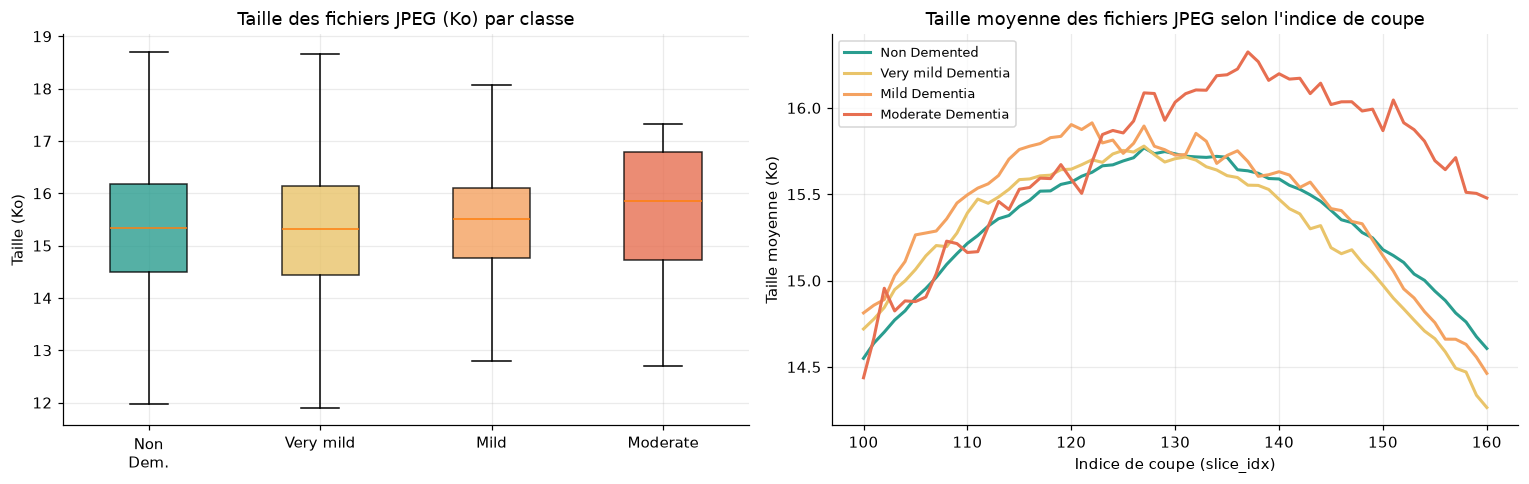

In [8]:
# Distribution de la taille des fichiers (Ko) par classe et par numéro de coupe
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Boxplot taille fichier par classe
data_kb = [df.loc[df["label"] == c, "file_size_kb"].values for c in CLASS_ORDER]
bp = axes[0].boxplot(data_kb, tick_labels=["Non\nDem.", "Very mild", "Mild", "Moderate"],
                     patch_artist=True, showfliers=False)
for patch, cls in zip(bp["boxes"], CLASS_ORDER):
    patch.set_facecolor(CLASS_COLORS[cls])
    patch.set_alpha(0.8)
axes[0].set_title("Taille des fichiers JPEG (Ko) par classe")
axes[0].set_ylabel("Taille (Ko)")

# Taille moyenne en fonction de slice_idx (proxy de la richesse en détails anatomiques)
for cls in CLASS_ORDER:
    sub = df[df["label"] == cls].groupby("slice_idx")["file_size_kb"].mean()
    axes[1].plot(sub.index, sub.values, label=cls, color=CLASS_COLORS[cls], linewidth=2)
axes[1].set_title("Taille moyenne des fichiers JPEG selon l'indice de coupe")
axes[1].set_xlabel("Indice de coupe (slice_idx)")
axes[1].set_ylabel("Taille moyenne (Ko)")
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()


## 5. Exploration Visuelle des IRM

Visualisons :
1. Un échantillon de coupes représentatives (coupe centrale `130`) pour chaque classe afin d'inspecter le cadrage, l'orientation et le ratio `496 × 248`.
2. L'évolution des coupes `100 → 160` pour un même volume MPR (illustration concrète de la continuité anatomique et du risque de fuite de données).
3. Les différents scans `mpr-1` à `mpr-4` d'un même patient à coupe identique.


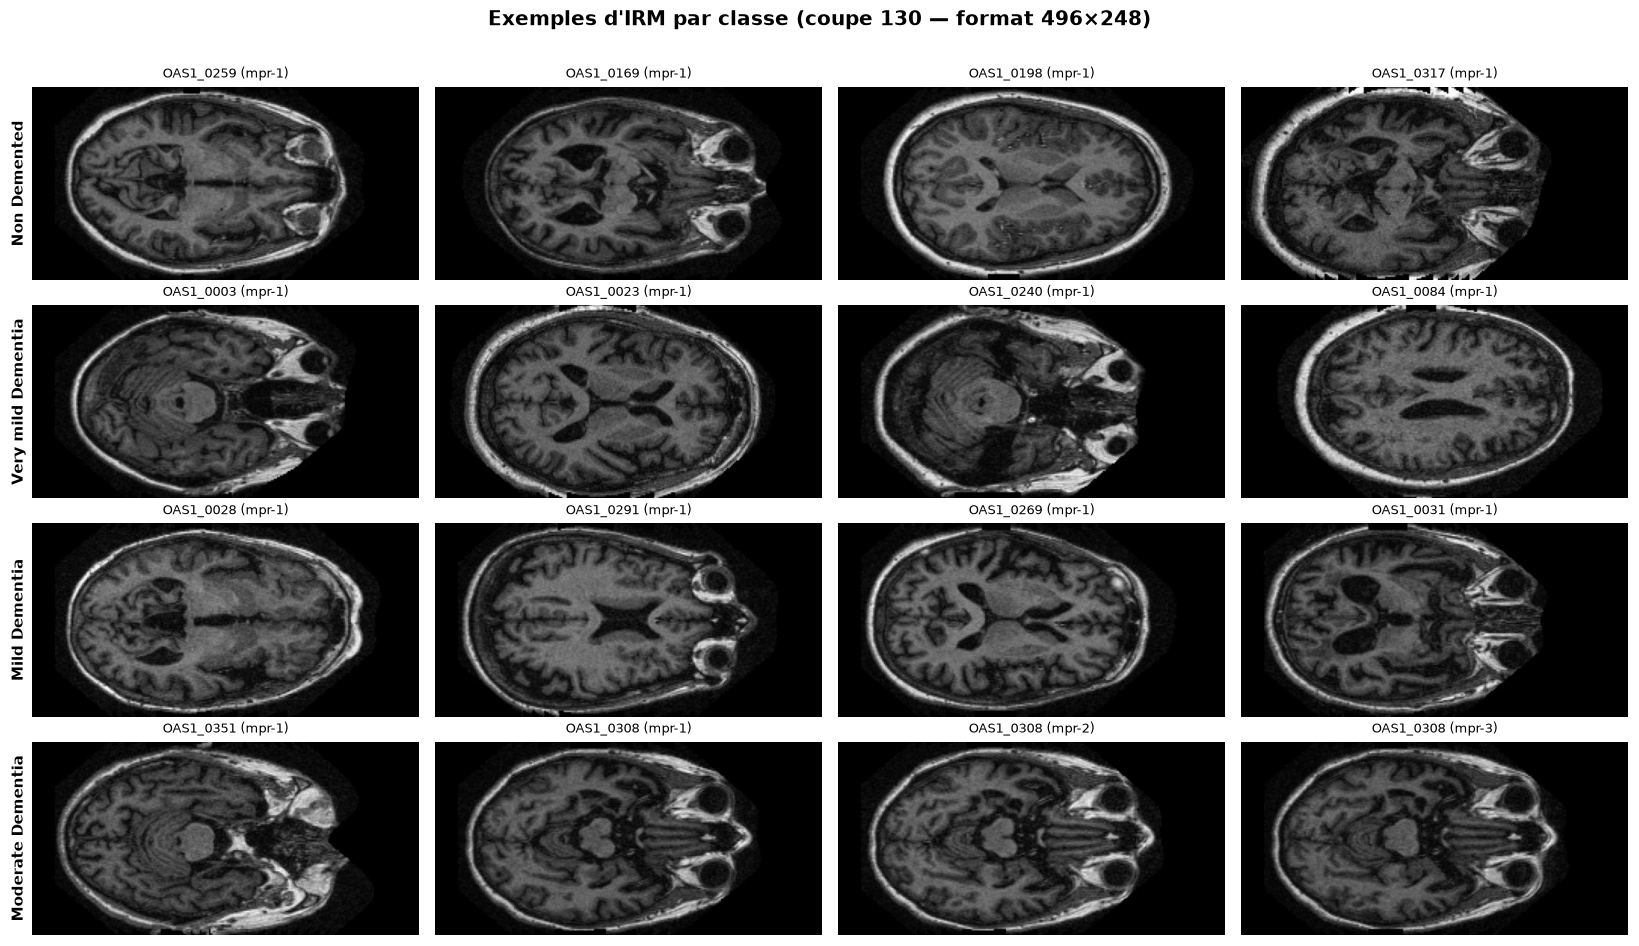

In [9]:
# 1. Grille d'exemples par classe (coupe 130, patients différents autant que possible)
fig, axes = plt.subplots(len(CLASS_ORDER), 4, figsize=(15, 8.5))

for row, cls in enumerate(CLASS_ORDER):
    sub = df[(df["label"] == cls) & (df["slice_idx"] == 130)]
    # Prendre des patients distincts si possible
    sub_unique = sub.drop_duplicates(subset=["subject_id"])
    chosen = sub_unique.sample(min(4, len(sub_unique)), random_state=SEED)
    if len(chosen) < 4:
        extra = sub[~sub["filepath"].isin(chosen["filepath"])].sample(4 - len(chosen), random_state=SEED)
        chosen = pd.concat([chosen, extra])
    for col, (_, rec) in enumerate(chosen.iterrows()):
        im = Image.open(rec["filepath"])
        axes[row, col].imshow(im)
        axes[row, col].set_title(f"{rec['subject_id']} ({rec['mpr_id']})", fontsize=8.5)
        axes[row, col].axis("off")
    axes[row, 0].set_ylabel(cls, fontsize=10, fontweight="bold")
    axes[row, 0].axis("on")
    axes[row, 0].set_xticks([])
    axes[row, 0].set_yticks([])
    for sp in axes[row, 0].spines.values():
        sp.set_visible(False)

fig.suptitle("Exemples d'IRM par classe (coupe 130 — format 496×248)", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


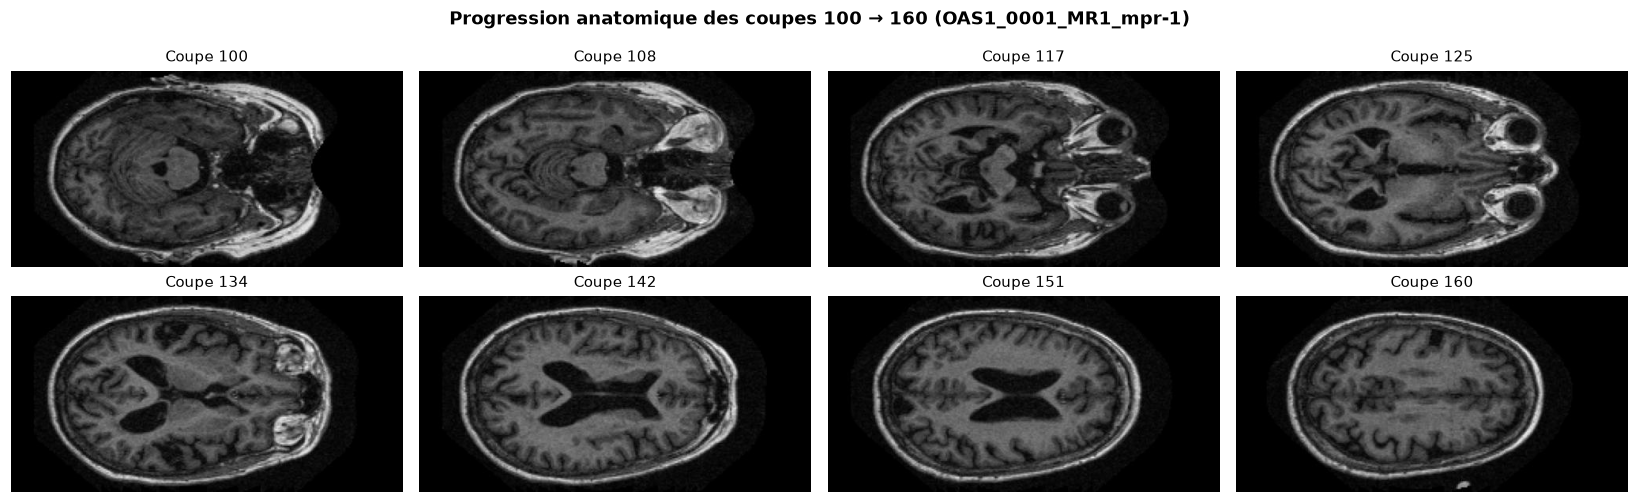

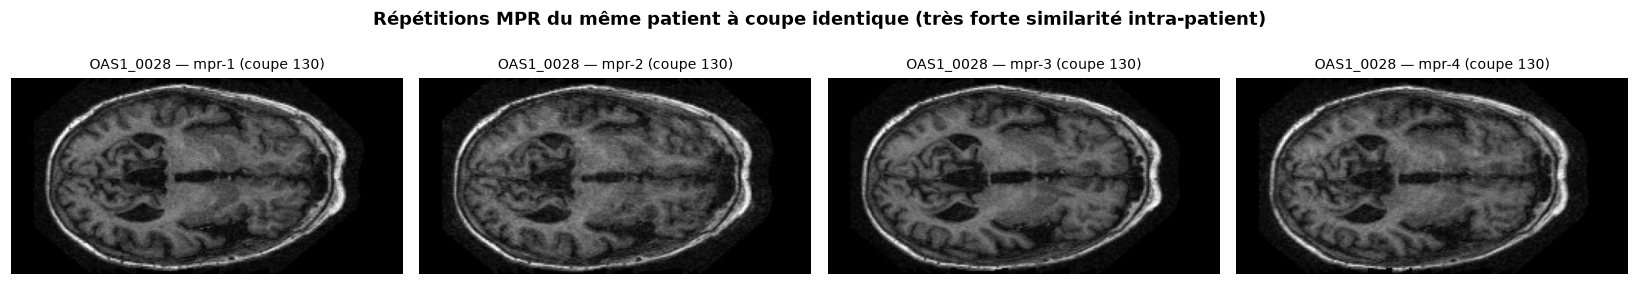

In [10]:
# 2. Séquence de coupes (100 -> 160) d'un même volume MPR
sample_vol = df[df["label"] == "Non Demented"]["volume_id"].iloc[0]
vol_df = df[df["volume_id"] == sample_vol].sort_values("slice_idx")
slice_picks = np.linspace(100, 160, 8, dtype=int)

fig, axes = plt.subplots(2, 4, figsize=(15, 4.8))
for ax, slc in zip(axes.flat, slice_picks):
    row = vol_df[vol_df["slice_idx"] == slc].iloc[0]
    ax.imshow(Image.open(row["filepath"]))
    ax.set_title(f"Coupe {slc}", fontsize=9.5)
    ax.axis("off")
fig.suptitle(f"Progression anatomique des coupes 100 → 160 ({sample_vol})", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# 3. Comparaison des scans mpr-1..mpr-4 d'un même patient à la même coupe (130)
sample_subj = df[(df["label"] == "Mild Dementia") & (df["slice_idx"] == 130)].groupby("subject_id").filter(lambda g: len(g) >= 4)["subject_id"].iloc[0]
mpr_df = df[(df["subject_id"] == sample_subj) & (df["slice_idx"] == 130)].sort_values("mpr_id").head(4)

fig, axes = plt.subplots(1, 4, figsize=(15, 2.8))
for ax, (_, row) in zip(axes, mpr_df.iterrows()):
    ax.imshow(Image.open(row["filepath"]))
    ax.set_title(f"{row['subject_id']} — {row['mpr_id']} (coupe 130)", fontsize=9)
    ax.axis("off")
fig.suptitle("Répétitions MPR du même patient à coupe identique (très forte similarité intra-patient)", fontsize=11.5, fontweight="bold")
plt.tight_layout()
plt.show()


## 6. Analyse Statistique des Pixels et Cartes Moyennes par Classe

Pour caractériser finement le signal d'intensité sans saturer la RAM, nous construisons un **échantillon stratifié** de **2 000 images** (jusqu'à 500 images par classe, dont l'intégralité des 488 images de `Moderate Dementia`), converties en niveaux de gris (`L`, puisque R = G = B).

Nous analysons :
- la distribution des intensités moyennes, écarts-types et proportions de fond noir (`pixel <= 5`) ;
- les histogrammes globaux d'intensité (tous pixels et hors fond noir) ;
- l'évolution du signal en fonction de l'indice de coupe (`slice_idx`) ;
- les **images moyennes**, **cartes d'écart-type** et **cartes de différence** par rapport à `Non Demented`.


In [11]:
# Échantillonnage stratifié (jusqu'à 500 images par classe)
N_PER_CLASS = 500
sample_df = pd.concat(
    [g.sample(min(N_PER_CLASS, len(g)), random_state=SEED) for _, g in df.groupby("label", observed=True)],
    ignore_index=True,
)
print("Effectifs de l'échantillon stratifié :")
print(sample_df["label"].value_counts())

def extract_pixel_stats(path):
    arr = np.asarray(Image.open(path).convert("L"), dtype=np.uint8)
    fg = arr[arr > 5]
    return (
        arr.mean(),
        arr.std(),
        float(np.median(arr)),
        float((arr <= 5).mean() * 100.0),
        float(fg.mean()) if fg.size > 0 else 0.0,
        float(fg.std()) if fg.size > 0 else 0.0,
        np.histogram(arr, bins=64, range=(0, 256))[0],
    )

with ThreadPoolExecutor(max_workers=12) as ex:
    res = list(ex.map(extract_pixel_stats, sample_df["filepath"].tolist()))

sample_df["mean_intensity"] = [r[0] for r in res]
sample_df["std_intensity"] = [r[1] for r in res]
sample_df["median_intensity"] = [r[2] for r in res]
sample_df["bg_black_pct"] = [r[3] for r in res]
sample_df["fg_mean_intensity"] = [r[4] for r in res]
sample_df["fg_std_intensity"] = [r[5] for r in res]
hists = np.stack([r[6] for r in res])

stats_table = sample_df.groupby("label", observed=True)[
    ["mean_intensity", "std_intensity", "bg_black_pct", "fg_mean_intensity"]
].agg(["mean", "std"]).round(2)
display(stats_table)

# Test non-paramétrique de Kruskal-Wallis entre classes (indicatif — observations corrélées intra-patient)
groups_mean = [sample_df.loc[sample_df["label"] == c, "mean_intensity"].values for c in CLASS_ORDER]
groups_bg = [sample_df.loc[sample_df["label"] == c, "bg_black_pct"].values for c in CLASS_ORDER]
kw_mean = stats.kruskal(*groups_mean)
kw_bg = stats.kruskal(*groups_bg)
print(f"Kruskal-Wallis (intensité moyenne) : H = {kw_mean.statistic:.2f}, p = {kw_mean.pvalue:.3e}")
print(f"Kruskal-Wallis (% fond noir <= 5)  : H = {kw_bg.statistic:.2f}, p = {kw_bg.pvalue:.3e}")
print("Note : p-values calculées au niveau coupe (non indépendantes intra-patient).")


Effectifs de l'échantillon stratifié :
label
Non Demented          500
Very mild Dementia    500
Mild Dementia         500
Moderate Dementia     488
Name: count, dtype: int64


mean_intensity       std_intensity       bg_black_pct  \
                             mean   std          mean   std         mean   
label                                                                      
Non Demented                42.27  7.06         44.83  4.34        33.11   
Very mild Dementia          40.02  5.34         44.59  3.23        34.52   
Mild Dementia               40.21  4.01         44.77  2.85        32.36   
Moderate Dementia           39.90  4.24         45.17  2.95        32.74   

                         fg_mean_intensity        
                     std              mean   std  
label                                             
Non Demented        7.22             62.90  6.97  
Very mild Dementia  7.58             61.01  4.85  
Mild Dementia       6.05             59.41  4.35  
Moderate Dementia   6.02             59.18  3.26

Kruskal-Wallis (intensité moyenne) : H = 72.72, p = 1.117e-15
Kruskal-Wallis (% fond noir <= 5)  : H = 33.30, p = 2.781e-07
Note : p-values calculées au niveau coupe (non indépendantes intra-patient).


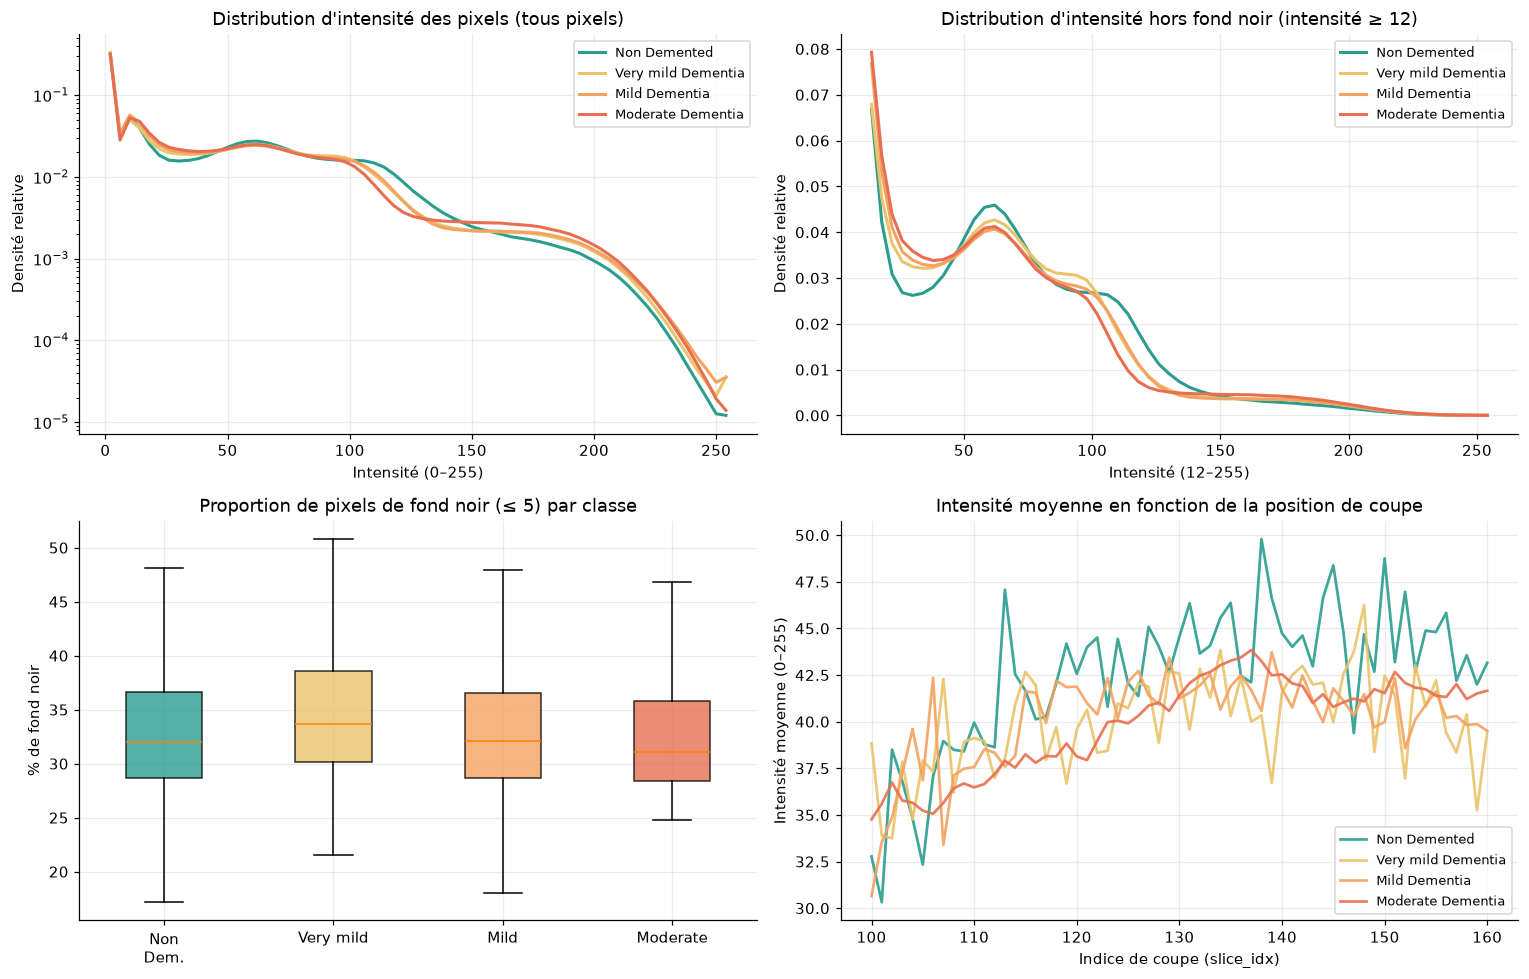

In [12]:
# Visualisation : histogrammes d'intensité + profil par coupe + distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
bin_centers = np.linspace(2, 254, 64)

# 1. Histogramme global (tous pixels)
for cls in CLASS_ORDER:
    mask = (sample_df["label"] == cls).values
    mean_hist = hists[mask].mean(axis=0)
    mean_hist = mean_hist / mean_hist.sum()
    axes[0, 0].plot(bin_centers, mean_hist, label=cls, color=CLASS_COLORS[cls], lw=2)
axes[0, 0].set_title("Distribution d'intensité des pixels (tous pixels)")
axes[0, 0].set_xlabel("Intensité (0–255)")
axes[0, 0].set_ylabel("Densité relative")
axes[0, 0].set_yscale("log")
axes[0, 0].legend(fontsize=8.5)

# 2. Histogramme hors fond noir (intensité > 12)
fg_bins = bin_centers >= 12
for cls in CLASS_ORDER:
    mask = (sample_df["label"] == cls).values
    mean_hist = hists[mask][:, fg_bins].mean(axis=0)
    mean_hist = mean_hist / mean_hist.sum()
    axes[0, 1].plot(bin_centers[fg_bins], mean_hist, label=cls, color=CLASS_COLORS[cls], lw=2)
axes[0, 1].set_title("Distribution d'intensité hors fond noir (intensité ≥ 12)")
axes[0, 1].set_xlabel("Intensité (12–255)")
axes[0, 1].set_ylabel("Densité relative")
axes[0, 1].legend(fontsize=8.5)

# 3. % de fond noir par classe
data_bg = [sample_df.loc[sample_df["label"] == c, "bg_black_pct"].values for c in CLASS_ORDER]
bp = axes[1, 0].boxplot(data_bg, tick_labels=["Non\nDem.", "Very mild", "Mild", "Moderate"],
                        patch_artist=True, showfliers=False)
for patch, cls in zip(bp["boxes"], CLASS_ORDER):
    patch.set_facecolor(CLASS_COLORS[cls])
    patch.set_alpha(0.8)
axes[1, 0].set_title("Proportion de pixels de fond noir (≤ 5) par classe")
axes[1, 0].set_ylabel("% de fond noir")

# 4. Intensité moyenne en fonction de l'indice de coupe
for cls in CLASS_ORDER:
    sub = sample_df[sample_df["label"] == cls].groupby("slice_idx")["mean_intensity"].mean()
    axes[1, 1].plot(sub.index, sub.values, label=cls, color=CLASS_COLORS[cls], lw=1.8, alpha=0.9)
axes[1, 1].set_title("Intensité moyenne en fonction de la position de coupe")
axes[1, 1].set_xlabel("Indice de coupe (slice_idx)")
axes[1, 1].set_ylabel("Intensité moyenne (0–255)")
axes[1, 1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()


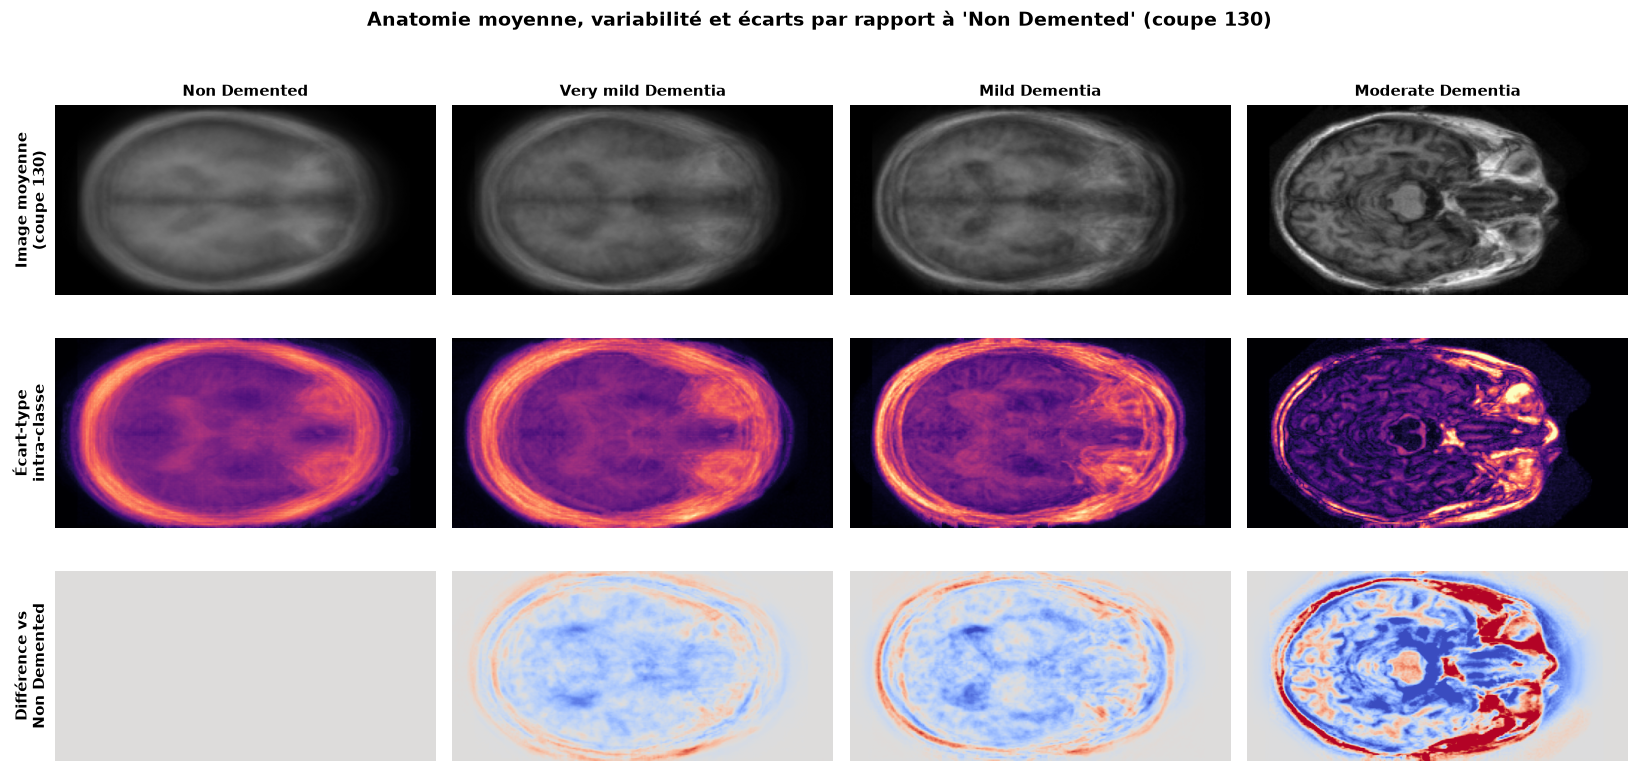

In [13]:
# Images moyennes, écarts-types et cartes de différence par classe (sur coupe 130 pour un alignement anatomique propre)
slice_target = 130
mean_imgs = {}
std_imgs = {}

for cls in CLASS_ORDER:
    sub_paths = df[(df["label"] == cls) & (df["slice_idx"] == slice_target)]["filepath"].tolist()
    if len(sub_paths) > 300:
        sub_paths = list(rng.choice(sub_paths, size=300, replace=False))
    stack = np.stack([np.asarray(Image.open(p).convert("L"), dtype=np.float32) for p in sub_paths])
    mean_imgs[cls] = stack.mean(axis=0)
    std_imgs[cls] = stack.std(axis=0)

fig, axes = plt.subplots(3, 4, figsize=(15, 7.2))
ref_img = mean_imgs["Non Demented"]

for col, cls in enumerate(CLASS_ORDER):
    # Ligne 1 : Image moyenne
    im0 = axes[0, col].imshow(mean_imgs[cls], cmap="gray", vmin=0, vmax=200)
    axes[0, col].set_title(cls, fontsize=10, fontweight="bold")
    axes[0, col].axis("off")

    # Ligne 2 : Carte d'écart-type
    im1 = axes[1, col].imshow(std_imgs[cls], cmap="magma", vmin=0, vmax=80)
    axes[1, col].axis("off")

    # Ligne 3 : Différence vs Non Demented
    diff = mean_imgs[cls] - ref_img
    im2 = axes[2, col].imshow(diff, cmap="coolwarm", vmin=-40, vmax=40)
    axes[2, col].axis("off")

row_titles = ["Image moyenne\n(coupe 130)", "Écart-type\nintra-classe", "Différence vs\nNon Demented"]
for r, title in enumerate(row_titles):
    axes[r, 0].axis("on")
    axes[r, 0].set_ylabel(title, fontsize=9.5, fontweight="bold")
    axes[r, 0].set_xticks([])
    axes[r, 0].set_yticks([])
    for sp in axes[r, 0].spines.values():
        sp.set_visible(False)

fig.suptitle("Anatomie moyenne, variabilité et écarts par rapport à 'Non Demented' (coupe 130)",
             fontsize=12.5, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


## 7. Analyse de la Structure Latente (PCA)

Projetons un échantillon stratifié d'images redimensionnées (`64 × 32`) par **ACP (PCA)** afin de répondre à une question fondamentale avant d'entraîner un modèle :
> *Qu'est-ce qui explique la plus grande part de variance visuelle entre deux images : la classe clinique (démence), la position de la coupe (`slice_idx`) ou l'identité du patient ?*


Variance expliquée par PC1 + PC2 : 20.2%
Variance expliquée par 10 PCs    : 50.4%
Variance expliquée par 30 PCs    : 70.3%


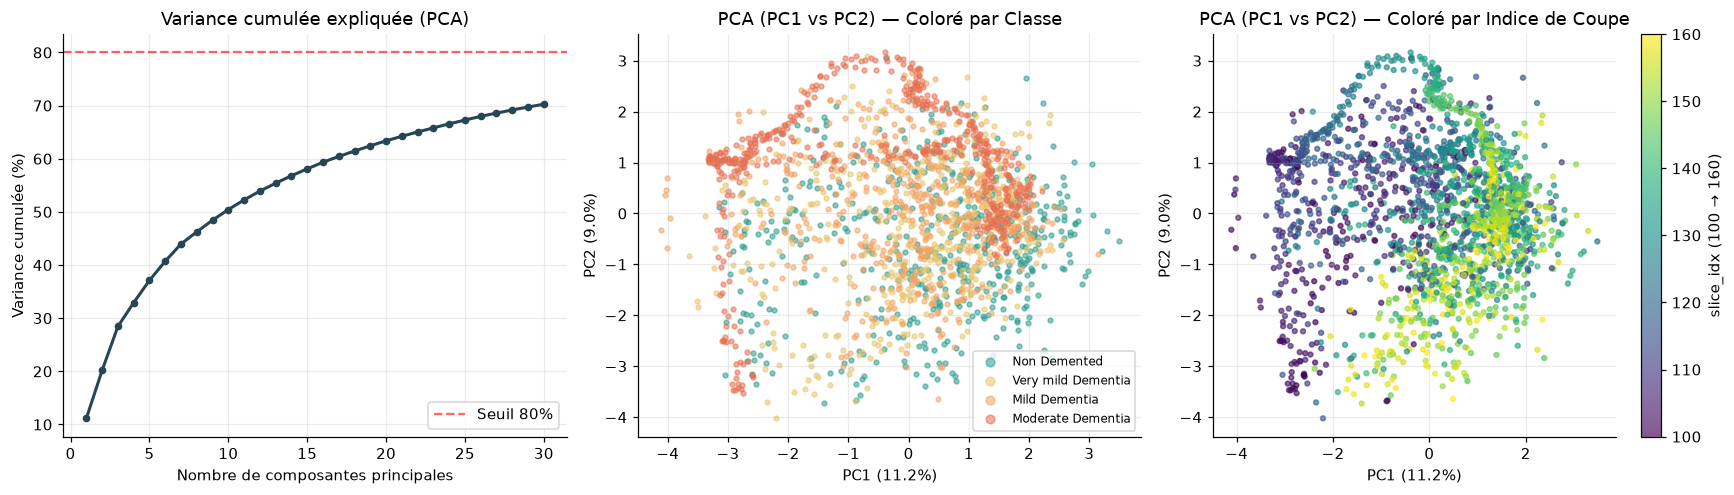

In [14]:
# Construction d'une matrice d'images redimensionnées (64x32) sur l'échantillon stratifié
def load_flat_thumb(path, size=(64, 32)):
    im = Image.open(path).convert("L").resize(size, Image.Resampling.BILINEAR)
    return np.asarray(im, dtype=np.float32).ravel() / 255.0

with ThreadPoolExecutor(max_workers=12) as ex:
    X_thumb = np.stack(list(ex.map(load_flat_thumb, sample_df["filepath"].tolist())))

pca = PCA(n_components=30, random_state=SEED)
X_pca = pca.fit_transform(X_thumb)
cum_var = np.cumsum(pca.explained_variance_ratio_) * 100

print(f"Variance expliquée par PC1 + PC2 : {cum_var[1]:.1f}%")
print(f"Variance expliquée par 10 PCs    : {cum_var[9]:.1f}%")
print(f"Variance expliquée par 30 PCs    : {cum_var[29]:.1f}%")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# 1. Scree plot (variance cumulée)
axes[0].plot(range(1, 31), cum_var, marker="o", markersize=4, color="#264653", lw=2)
axes[0].axhline(80, color="red", linestyle="--", alpha=0.6, label="Seuil 80%")
axes[0].set_title("Variance cumulée expliquée (PCA)")
axes[0].set_xlabel("Nombre de composantes principales")
axes[0].set_ylabel("Variance cumulée (%)")
axes[0].legend()

# 2. Projection PC1 vs PC2 colorée par classe
for cls in CLASS_ORDER:
    m = (sample_df["label"] == cls).values
    axes[1].scatter(X_pca[m, 0], X_pca[m, 1], s=10, alpha=0.55, label=cls, color=CLASS_COLORS[cls])
axes[1].set_title("PCA (PC1 vs PC2) — Coloré par Classe")
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
axes[1].legend(fontsize=8, markerscale=1.8)

# 3. Projection PC1 vs PC2 colorée par indice de coupe
sc = axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=sample_df["slice_idx"], cmap="viridis", s=10, alpha=0.65)
axes[2].set_title("PCA (PC1 vs PC2) — Coloré par Indice de Coupe")
axes[2].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
axes[2].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
cbar = plt.colorbar(sc, ax=axes[2])
cbar.set_label("slice_idx (100 → 160)")

plt.tight_layout()
plt.show()


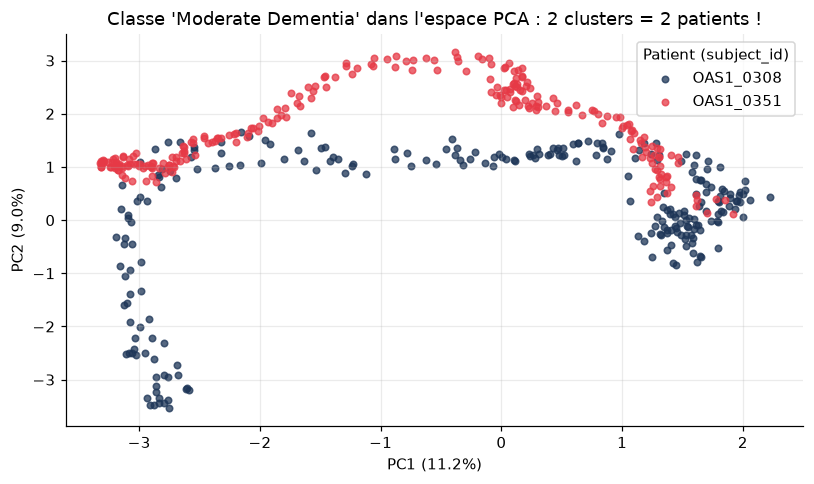

In [15]:
# Vérification : séparation des 2 patients de Moderate Dementia dans l'espace PCA
mod_mask = (sample_df["label"] == "Moderate Dementia").values
mod_df = sample_df[mod_mask].reset_index(drop=True)
X_mod_pca = X_pca[mod_mask]

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for subj, color in zip(sorted(mod_df["subject_id"].unique()), ["#1d3557", "#e63946"]):
    m = (mod_df["subject_id"] == subj).values
    ax.scatter(X_mod_pca[m, 0], X_mod_pca[m, 1], s=18, alpha=0.75, label=subj, color=color)
ax.set_title("Classe 'Moderate Dementia' dans l'espace PCA : 2 clusters = 2 patients !")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.legend(title="Patient (subject_id)")
plt.tight_layout()
plt.show()


### Conclusions de l'analyse en composantes principales (PCA)

1. **Les 4 classes cliniques ne sont pas séparables linéairement dans l'espace des pixels bruts** : dans le graphique *Coloré par Classe*, les nuages de points des 4 classes se chevauchent presque entièrement. Les marqueurs d'Alzheimer (atrophie corticale, élargissement des ventricules, hippocampe) sont des signaux **subtils et localisés**, bien plus faibles que les grosses variations globales de forme ou de luminosité.
2. **L'axe principal de variance (PC1 = 11,2 %) est dominé par la position de la coupe (`slice_idx`, corrélation $r = 0{,}57$)** : dans le graphique *Coloré par Indice de Coupe*, on observe un gradient continu net de la coupe `100` à `160`. Autrement dit, la position anatomique pèse plus lourd dans la variance brute que la maladie elle-même.
3. **L'identité anatomique du patient structure fortement l'espace (PC2 = 9,0 %)** : sur le graphique dédié à `Moderate Dementia`, les deux patients (`OAS1_0308` et `OAS1_0351`) forment deux nuages nettement décalés (sur PC2 : moyenne $0{,}13$ vs $1{,}69$). Un modèle a donc beaucoup plus de facilité à **mémoriser la forme du cerveau d'un patient** qu'à apprendre la pathologie.
4. **70,3 % de la variance est capturée par 30 composantes** (50,4 % sur 10 composantes), ce qui traduit une forte redondance spatiale des images IRM.

> **Ce qu'il faut en retenir pour la suite :**
> - Un modèle linéaire ou trop simple sur pixels bruts ne suffira pas : il faut un **CNN / Transfer Learning** capable d'extraire des motifs anatomiques fins.
> - Le **split strict par patient (`subject_id`)** est non négociable : sinon le modèle exploite la signature anatomique individuelle (effet patient) au lieu de généraliser à la démence.


## 8. Synthèse & Recommandations pour la Modélisation

### Constats clés de l'EDA
1. **Structure hiérarchique stricte** : 86 437 images `.jpg` issues de **347 patients uniques** et **1 417 volumes MPR**, chaque volume comprenant exactement **61 coupes** (`slice_idx` de 100 à 160). Aucun patient n'apparaît dans plusieurs classes.
2. **Déséquilibre extrême** :
   - `Non Demented` : 67 222 images (**77,8 %**) / 266 patients
   - `Very mild Dementia` : 13 725 images (**15,9 %**) / 58 patients
   - `Mild Dementia` : 5 002 images (**5,8 %**) / 21 patients
   - `Moderate Dementia` : 488 images (**0,56 %**) / **2 patients seulement** (ratio 137,7:1)
3. **Propriétés des images** : toutes les images sont valides (0 fichier corrompu), de dimension uniforme **496 × 248** (ratio 2:1), enregistrées en `RGB` mais avec des canaux R, G, B identiques (fausses RGB → niveaux de gris).
4. **Forte redondance intra-patient** : les coupes consécutives et les scans `mpr-1..4` d'un même patient sont quasi identiques. En PCA, la variance globale est dominée par la position de la coupe (`slice_idx`) et l'identité anatomique du patient (visible très clairement sur les 2 patients de `Moderate Dementia`).

### Recommandations concrètes avant entraînement
- **Split strict par patient (`GroupShuffleSplit` / `StratifiedGroupKFold` sur `subject_id`)** : ne **jamais** splitter aléatoirement par image, sous peine de data leakage massif.
- **Traitement de `Moderate Dementia` (2 patients)** :
  - Pour une classification à 4 classes, au maximum 1 patient peut aller en train et 1 en validation/test (très forte variance d'évaluation).
  - Envisager en parallèle une formulation **3 classes** (`Non Demented`, `Very mild`, `Mild + Moderate`) ou **binaire** (`Non Demented` vs `Demented`) pour une évaluation robuste en validation croisée 5-fold par patient.
- **Prétraitement** :
  - Convertir en **1 canal** (`L`) ou conserver 3 canaux uniquement si un backbone ImageNet pré-entraîné est utilisé.
  - Préserver le ratio **2:1** lors du redimensionnement (ex. `256 × 128` ou `224 × 112`) ou recadrer la bande de fond noir inutile.
  - Normaliser les intensités par image ou par volume (z-score sur le cerveau hors fond noir) pour réduire l'effet contraste inter-scans.
- **Gestion du déséquilibre & métriques** :
  - Utiliser `class_weight` (ou Focal Loss) + augmentation de données modérée (petites rotations/translations, légères variations de contraste — éviter le flip vertical).
  - Évaluer **au niveau patient** (agrégation des probabilités des 61 coupes par moyenne/vote majoritaire) avec **Balanced Accuracy**, **Macro-F1** et **matrice de confusion normalisée**, plutôt que l'accuracy brute par image.
